# API Data Report

Name: Joseph Eberts<br>Date: October 19, 2026

# Hypothesis:
Longer Bluesky posts tend to receive more likes than shorter posts.

# Theoretical Application

This report will explore if the length of social media content and audience engagement such as likes is related. Longer posts usually provide more information while shorter posts are usually quicker to read with less info.

# Statistical Application

Post length will be measured by character count and will be compared with the number of likes each post receives.



# Variables:
- Post length (number of characters)
- Number of likes
- Number of reposts
- Number of replies
- Author's follower count

In [19]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [20]:
url = "https://api.bsky.app/xrpc/app.bsky.feed.searchPosts"

params = {
    "q": "design",
    "limit": 100
}

response = requests.get(url, params=params, timeout=10)

print(response.status_code)

200


In [21]:
data = response.json()

posts = data["posts"]

print(len(posts))

99


In [22]:
posts_df = pd.DataFrame([
    {
        "text": post["record"]["text"],
        "post_length": len(post["record"]["text"]),
        "likes": post["likeCount"],
        "reposts": post["repostCount"],
        "replies": post["replyCount"],
        "author_did": post["author"]["did"]
    }
    for post in posts
])

posts_df.head()

,text,post_length,likes,reposts,replies,author_did
0,Heya :))) Just a personal hobby project for my...,256,0,0,0,did:plc:lg7pe2ilk6efm422kizr4hpb
1,"When Amna launched Paper Pixel, a CV and portf...",300,0,0,0,did:plc:bh53ugou6othzo23jikcuevj
2,"As a graphic designer, I LOOOOVE learning abou...",164,0,0,0,did:plc:3l63rlyceg2axxpt4xopfndc
3,I can show sympathy. I am human. That's why I ...,296,1,1,0,did:plc:oepw27uo4z33crpqj7wmbfva
4,ASIC Design Engineer - New College Grad 2026 -...,101,0,0,0,did:plc:voa5jj4mjj2u76o7cp6qanjz


In [23]:
profile_url = "https://api.bsky.app/xrpc/app.bsky.actor.getProfile"

profiles = []

for actor in posts_df["author_did"].drop_duplicates().head(10):
    params = {"actor": actor}

    response = requests.get(profile_url, params=params, timeout=10)

    if response.status_code == 200:
        profile = response.json()

        profiles.append({
            "author_did": profile["did"],
            "followers": profile.get("followersCount")
        })

profiles_df = pd.DataFrame(profiles)

profiles_df.head()

,author_did,followers
0,did:plc:lg7pe2ilk6efm422kizr4hpb,7853
1,did:plc:bh53ugou6othzo23jikcuevj,2825
2,did:plc:3l63rlyceg2axxpt4xopfndc,347
3,did:plc:oepw27uo4z33crpqj7wmbfva,11
4,did:plc:voa5jj4mjj2u76o7cp6qanjz,575


For the above line of code:</br>I used chat gpt to help me collect profile information for authors like their follower counts.

In [24]:
final_df = pd.merge(
    posts_df,
    profiles_df,
    on="author_did",
    how="left"
)

final_df.head()

,text,post_length,likes,reposts,replies,author_did,followers
0,Heya :))) Just a personal hobby project for my...,256,0,0,0,did:plc:lg7pe2ilk6efm422kizr4hpb,7853.0
1,"When Amna launched Paper Pixel, a CV and portf...",300,0,0,0,did:plc:bh53ugou6othzo23jikcuevj,2825.0
2,"As a graphic designer, I LOOOOVE learning abou...",164,0,0,0,did:plc:3l63rlyceg2axxpt4xopfndc,347.0
3,I can show sympathy. I am human. That's why I ...,296,1,1,0,did:plc:oepw27uo4z33crpqj7wmbfva,11.0
4,ASIC Design Engineer - New College Grad 2026 -...,101,0,0,0,did:plc:voa5jj4mjj2u76o7cp6qanjz,575.0


In [25]:
final_df[["post_length", "likes", "reposts", "replies", "followers"]].describe()

,post_length,likes,reposts,replies,followers
count,99.000000,99.000000,99.000000,99.000000,10.000000
mean,186.030303,0.888889,0.101010,0.252525,1365.900000
std,91.896954,2.307436,0.364074,0.481143,2426.168055
min,0.000000,0.000000,0.000000,0.000000,11.000000
25%,107.500000,0.000000,0.000000,0.000000,117.500000
50%,203.000000,0.000000,0.000000,0.000000,472.500000
75%,274.500000,1.000000,0.000000,0.000000,913.750000
max,301.000000,15.000000,2.000000,2.000000,7853.000000


For this step I used chat gpt to help me summarize the variables so I could understand the data before analyzing my hypothesis.

In [26]:
import matplotlib.pyplot as plt

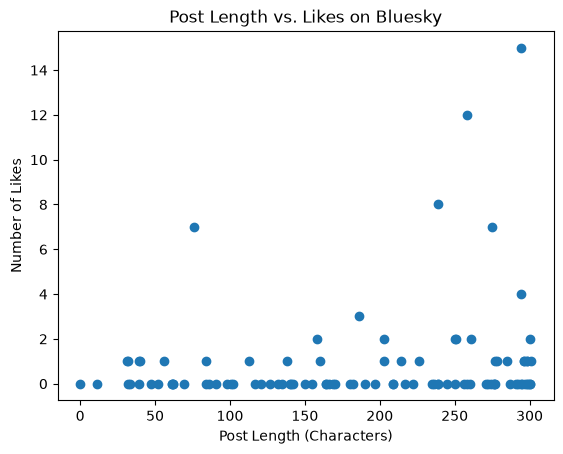

In [27]:
plt.scatter(final_df["post_length"], final_df["likes"])

plt.xlabel("Post Length (Characters)")
plt.ylabel("Number of Likes")
plt.title("Post Length vs. Likes on Bluesky")

plt.show()

In [28]:
final_df["post_length"].corr(final_df["likes"])

np.float64(0.1804251648271567)

For this step I had chat gpt help me calculate the correlation between post length and likes to see whether the two variables are related.

# Bluesky API Endpoints

1. app.bsky.feed.searchPosts

This endpoint searches for posts matching a word or phrase. I used it to collect posts that contained "design," including their text, likes, reposts, and replies. From there I then used the text to calculate post length and the like count which helped me test my hypothesis.

2. app.bsky.actor.getProfile

This endpoint collects profile information such as follower counts. I used this info to see whether an author's audience size  effects the number of likes their posts receive.

# Data Reliability

This API provides data directly from Bluesky itself, but the data isnt perfect. Like and follower counts can change over time, as well as missing information that might have affected the results. Since I only collected a small sample of posts (100), my findings may not apply to all Bluesky users or every test.

# Conclusion and Limitations

Since my results were 0.175, this shows that there was a weaker positive relationship but not consistent relationship between post length and likes. This means longer posts tended to receive slightly more likes but the relationship was not strong or consistent. 

If the results were closer to -1, there would be a strong negative relationship and if the results were close to 1, there would be a strong positive relationship. Therefore my results were on the positive side but not quite near 1.

My data was limited to posts containing "design" and a small sample of 100 authors. In the future I could collect more posts using different search terms and compare accounts with different follower counts to see what affects likes.